<div style="background-color: #f5f5f5; padding: 20px; border-radius: 10px; border: 1px solid #e0e0e0;">
<table style="width:100%; border:none;">
  <tbody><tr style="border:none;">
    <td style="width:20%; text-align:center; border:none; vertical-align:middle;">
      <img src="https://i.ibb.co/pjbk15cs/UI-Logo.png" alt="UI Logo" width="100">
    </td>
    <td style="width:60%; text-align:center; border:none; vertical-align:middle;">
      <h1 style="margin:0; color:#333;">University of Isfahan</h1>
      <h2 style="margin:0; color:#555; font-weight:normal;">Faculty of Mathematics and Statistics</h2>
      <br/>
      <hr style="border: 1px solid #ccc; margin-top:15px; margin-bottom:15px;">
      <h3 style="margin:0; color:#0056b3;">Sixth Practical Homework: PCA & Anomaly Detection</h3>
      <br/>
      <h4 style="margin:0; font-size: 1.1em; color: #333; line-height: 1.6; margin-top: 15px; display: inline-block;">
        <strong>Course:</strong> Machine Learning<br>
        <strong>Instructor:</strong> Dr. Mohsen Alambardar<br>
        <strong>Semester:</strong> Fall 1404-1405
      </h4>
    </td>
    <td style="width:20%; text-align:center; border:none; vertical-align:middle;">
      <img src="https://i.ibb.co/pjbk15cs/UI-Logo.png" alt="UI Logo" width="100">
    </td>
  </tr>
</tbody></table>
</div>

<div style="background-color: #f5f5f5; border: 1px solid #f5f5f5; padding: 20px; border-radius: 10px; margin-top: 25px; margin-bottom: 25px;">
  
  <h3 style="text-align: center; margin-top: 0; color: #0056b3;">Student Information</h3>
  <p style="text-align: center; color: #555; margin-bottom: 20px; margin-top: 0;">
    Please fill in your details below.
  </p>

  <table style="width: 60%; margin-left: auto; margin-right: auto; border: none; font-size: 1.1em; color: #333;">
    <tbody>
      <tr>
        <td style="text-align: right; padding: 8px; width: 35%;"><strong>Student Name:</strong></td>
        <td style="text-align: left; padding: 8px;"><em>Hosna Soltanolkottabi</em></td> 
      </tr>
      <tr>
        <td style="text-align: right; padding: 8px;"><strong>Student ID:</strong></td>
        <td style="text-align: left; padding: 8px;"><em></em></td>  
      </tr>
    </tbody>
  </table>
  
</div>

# **HW6-P: Dimensionality Reduction & Anomaly Detection**

In this homework, we will explore the **Fashion-MNIST** dataset. Unlike simple digit recognition, this dataset contains images of clothing (T-shirts, trousers, pullovers, dresses, coats, sandals, shirts, sneakers, bags, and ankle boots).

**Our Goals:**
1.  **Understand PCA:** Implement Principal Component Analysis (PCA) mathematically from scratch to understand covariance and eigenvectors.
2.  **Visualizing Compression:** Use PCA to compress images and visualize what information is preserved vs. lost.
3.  **Anomaly Detection:** Use the reconstruction error from PCA to build a practical Anomaly Detection system that can distinguish Sneakers (outliers) from T-Shirts (normal data).

## 1. **Setup and Data Loading**

We will use `sklearn.datasets.fetch_openml` to load the Fashion-MNIST dataset. This might take a minute to download the first time.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import fetch_openml
from sklearn.model_selection import train_test_split
from sklearn.decomposition import PCA
from sklearn.metrics import precision_recall_curve, confusion_matrix, ConfusionMatrixDisplay

# Set default figure size
plt.rcParams['figure.figsize'] = (10, 6)
plt.style.use('ggplot')

Loading Fashion-MNIST (this may take a moment)...
Data Loaded. Shape: (70000, 784)


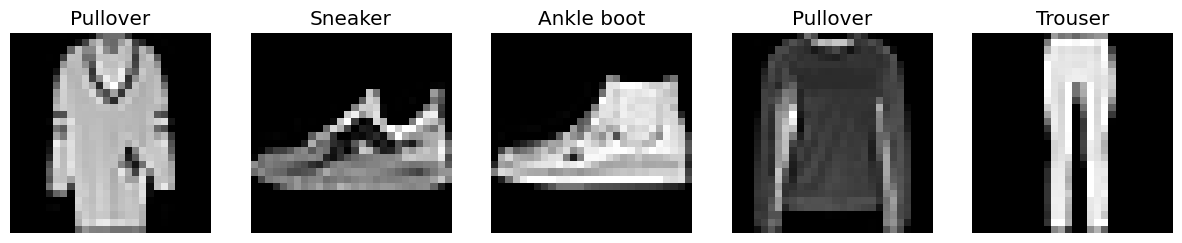

In [2]:
# Load Fashion-MNIST data
print("Loading Fashion-MNIST (this may take a moment)...")

try:
    # Attempt 1: Fetch by stable Data ID (40996 is Fashion-MNIST)
    # We remove 'version' as ID is unique
    X, y = fetch_openml(data_id=40996, return_X_y=True, as_frame=False)
except Exception:
    try:
        # Attempt 2: Fetch by name 'Fashion-MNIST' (capitalized) without version
        X, y = fetch_openml('Fashion-MNIST', return_X_y=True, as_frame=False)
    except Exception:
        # Attempt 3: Try the specific string 'fashion-mnist_784' without version
        X, y = fetch_openml('fashion-mnist_784', return_X_y=True, as_frame=False)

# Normalize pixel values to be between 0 and 1
X = X / 255.0

# Convert labels to integers
y = y.astype(int)

print(f"Data Loaded. Shape: {X.shape}")

# Labels mapping for reference
class_names = ['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat',
               'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']

# Plot a few random images
fig, axes = plt.subplots(1, 5, figsize=(15, 3))
for i, ax in enumerate(axes):
    idx = np.random.randint(0, len(X))
    ax.imshow(X[idx].reshape(28, 28), cmap='gray')
    ax.set_title(class_names[y[idx]])
    ax.axis('off')
plt.show()

---

## 2. **Part 1: PCA Implementation**

### 2.1. **From Scratch** (`#TODO`)

Before using the library, let's ensure we understand the math. PCA relies on the **Covariance Matrix** and **Eigenvalue Decomposition**.

**The Steps:**
1.  **Standardize** the data (Center the mean to 0).
2.  Compute the **Covariance Matrix** $\Sigma$: 
    $$ \Sigma = \frac{1}{m-1} X^T X $$
    *(Assuming X is already centered)*
3.  Compute **Eigenvalues** ($\lambda$) and **Eigenvectors** ($v$) of $\Sigma$.
4.  Sort them from largest $\lambda$ to smallest.

For this part, to save computation time, we will use a subset of 5000 images.

In [3]:
# Use a subset for the manual part
X_subset = X[:5000]

# --- YOUR TASK ---

# 1. Mean Centering: Subtract the mean of each feature from the dataset
# TODO: Calculate mean and center the data
X_mean = np.mean(X_subset, axis=0)
X_centered = X_subset - X_mean

# 2. Compute Covariance Matrix: (X_T * X) / (m - 1)
# Hint: You can use np.dot or the @ operator. m is the number of samples.
# TODO: Compute covariance matrix
m = X_centered.shape[0]
cov_matrix = (X_centered.T @ X_centered) / (m - 1)

# 3. Eigen Decomposition: Use np.linalg.eigh (better for symmetric matrices)
# TODO: Compute eigenvalues and eigenvectors
eigen_values, eigen_vectors = np.linalg.eigh(cov_matrix)

# 4. Sort Eigenvalues and Vectors in descending order
# np.linalg.eigh returns them in ascending order, so we need to reverse them.
# TODO: Sort them descending
sorted_indices = np.argsort(eigen_values)[::-1]
sorted_eigenvalues = eigen_values[sorted_indices]
sorted_eigenvectors = eigen_vectors[:,sorted_indices]

# --- End of YOUR TASK ---

print(f"Top 5 Eigenvalues: {sorted_eigenvalues[:5]}")

Top 5 Eigenvalues: [19.73294133 12.49988574  4.07463338  3.43559102  2.77205626]


### 2.2. **Using `sklearn` PCA** (`#TODO`)

Now that we've done it the hard way, let's use the efficient `sklearn` implementation on the full dataset. We want to find the number of components needed to preserve **95%** of the variance.

Number of components to explain 95% variance: 188


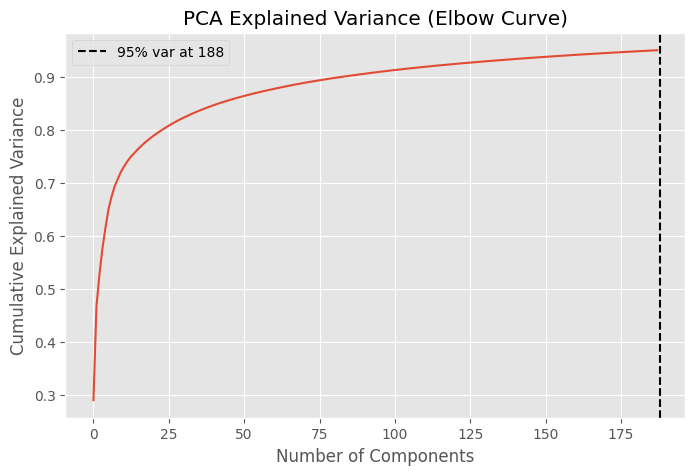

In [4]:
# --- YOUR TASK ---

# TODO: Initialize PCA to keep 0.95 variance (n_components=0.95)
pca = PCA(n_components=0.95)

# TODO: Fit PCA on the full dataset X (Use the original X, PCA handles centering internally)
pca.fit(X)

# --- End of YOUR TASK ---

n_components = pca.n_components_
print(f"Number of components to explain 95% variance: {n_components}")

# Plot the Elbow Curve
plt.figure(figsize=(8, 5))
plt.plot(np.cumsum(pca.explained_variance_ratio_))
plt.xlabel('Number of Components')
plt.ylabel('Cumulative Explained Variance')
plt.title('PCA Explained Variance (Elbow Curve)')
plt.grid(True)
plt.axvline(n_components, color='k', linestyle='--', label=f'95% var at {n_components}')
plt.legend()
plt.show()

### 2.3. **Analysis: Question 1** (`#TODO`)

**Q1:** The original images have $28 \times 28 = 784$ pixels (dimensions). You found a number $k$ (components) above. What does this reduction from $784$ to $k$ tell you about the redundancy of information in the image pixels?

**Answer:**
در واقع 784 پیکسل اطلاعات اضافی به همراه داشتند که ما نیاز نداریم و با تعداد کمتر پیکسل (188) اطلاعات مهم در دسترس ما همچنان قرار دارد


---

## 3. **Part 2: Image Compression & Reconstruction**

To visualize what information is preserved, we will: 
1. Project images into the lower-dimensional space (Transform).
2. Project them back to the original space (Inverse Transform).
3. Compare the original and reconstructed images.

### 3.1. **Transform & Compare** (`#TODO`)

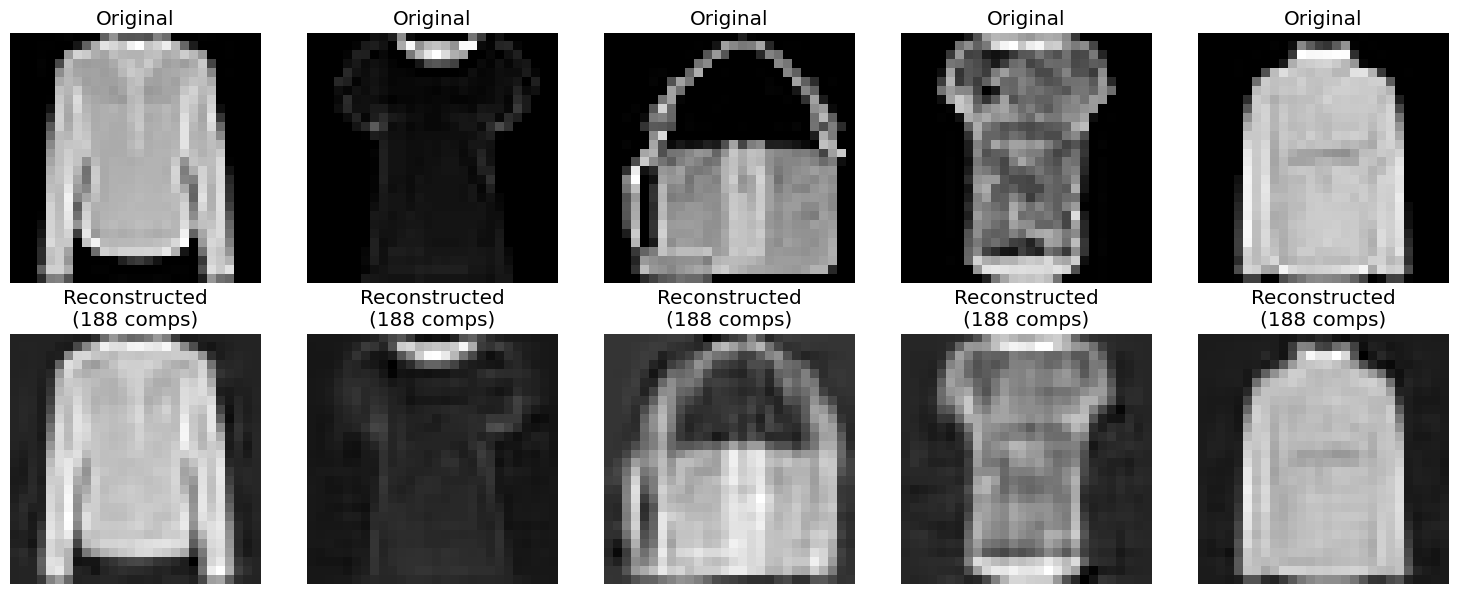

In [5]:
# Select 5 random images
indices = np.random.choice(len(X), 5, replace=False)
original_images = X[indices]

# --- YOUR TASK ---

# TODO: Transform the images to the latent space (compressed)
compressed_images = pca.transform(original_images)

# TODO: Inverse transform the compressed images back to original space (reconstructed)
reconstructed_images = pca.inverse_transform(compressed_images)

# --- End of YOUR TASK ---

# Plotting
fig, axes = plt.subplots(2, 5, figsize=(15, 6))
for i in range(5):
    # Original
    axes[0, i].imshow(original_images[i].reshape(28, 28), cmap='gray')
    axes[0, i].set_title("Original")
    axes[0, i].axis('off')
    
    # Reconstructed
    axes[1, i].imshow(reconstructed_images[i].reshape(28, 28), cmap='gray')
    axes[1, i].set_title(f"Reconstructed\n({n_components} comps)")
    axes[1, i].axis('off')

plt.tight_layout()
plt.show()

### 3.2. **Analysis: Question 2** (`#TODO`)

**Q2:** Look at the reconstructed images. They appear slightly "blurry". Explain why this happens in terms of the Variance you decided to keep (95%) vs. the Variance you discarded (5%). What exactly did we discard?

**Answer:**
بردار ویژه هایی که نادیده گرفتیم(بردار ویژه های نظیر مقادیر ویژه های کمتر) در نمایش جزئیات تصویر تاثیر دارند به همین دلیل با حذف آن ها تصویر کمی مات شده است

---

## 4. **Part 3: Anomaly Detection via Reconstruction Error**

This is a cool practical application. PCA learns the patterns of the data it is trained on. 

* If we train PCA **only** on T-Shirts (Class 0), it will learn to reconstruct T-Shirts very well.
* If we then show it a Sneaker (Class 7), it will try to reconstruct the Sneaker using the "rules" of T-Shirts. It will fail, leading to a high **Reconstruction Error**.

We can use this Error as a score to detect anomalies!

**Experiment Setup:**
1.  **Training Set:** Only T-Shirts.
2.  **Test Set:** A mix of T-Shirts (Normal, $y=0$) and Sneakers (Anomaly, $y=1$).

### 4.1. **Prepare Anomaly Detection Dataset**

In [6]:
# 1. Select T-Shirts (Label 0) and Sneakers (Label 7)
X_tshirts = X[y == 0]
X_sneakers = X[y == 7]

# 2. Split T-Shirts into Train and Validation
# We will train PCA ONLY on X_train_normal
X_train_normal, X_val_normal = train_test_split(X_tshirts, test_size=0.2, random_state=42)

# 3. Create a Test set mixing Normal (T-shirts) and Anomalies (Sneakers)
# Let's take 500 normal samples and 500 anomaly samples
X_test_normal = X_val_normal[:500]
X_test_anomaly = X_sneakers[:500]

X_test_combined = np.concatenate([X_test_normal, X_test_anomaly])

# Create labels for evaluation: 0 for Normal, 1 for Anomaly
y_test_combined = np.concatenate([np.zeros(len(X_test_normal)), np.ones(len(X_test_anomaly))])

print(f"Training PCA on {len(X_train_normal)} T-shirts.")
print(f"Testing on {len(X_test_combined)} images ({np.sum(y_test_combined==0)} Normal, {np.sum(y_test_combined==1)} Anomaly).")

Training PCA on 5600 T-shirts.
Testing on 1000 images (500 Normal, 500 Anomaly).


### 4.2. **PCA Training & Reconstruction Error** (`#TODO`)

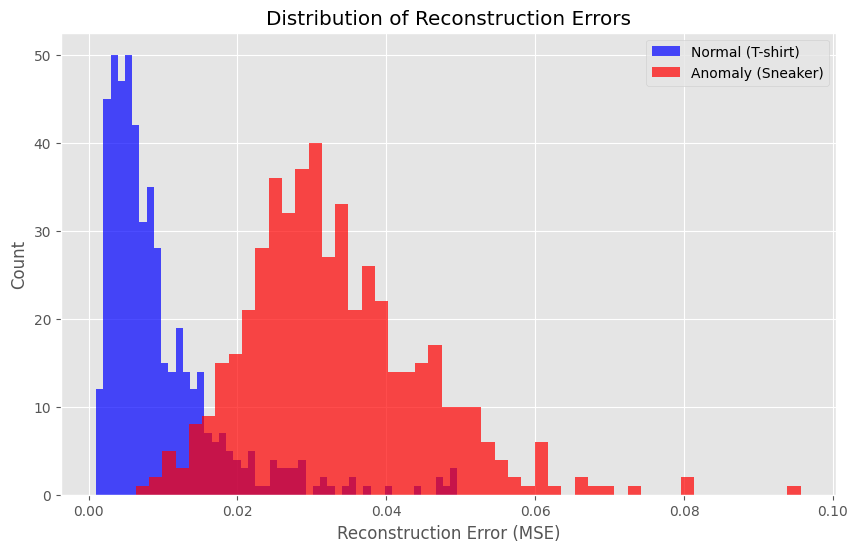

In [7]:
# --- YOUR TASK ---

# 1. Train PCA on Normal Data Only
# Use n_components=30 for a tighter bottleneck (forces model to learn general shape only)
# TODO: Initialize and fit PCA on X_train_normal
pca_ad = PCA(n_components=30)
pca_ad.fit(X_train_normal)

# 2. Reconstruct the Combined Test Set
# TODO: Transform and then Inverse Transform X_test_combined
X_test_encoded = pca_ad.transform(X_test_combined)
X_test_reconstructed = pca_ad.inverse_transform(X_test_encoded)

# 3. Calculate Reconstruction Error (MSE)
# Error = Mean Squared Error between Original and Reconstructed for EACH image
# Shape should be (1000,)
# TODO: Calculate MSE per sample
reconstruction_error = np.mean((X_test_combined-X_test_reconstructed)**2, axis=1)

# --- End of YOUR TASK ---

# Visualization: Histogram of errors
plt.figure(figsize=(10, 6))
plt.hist(reconstruction_error[y_test_combined==0], bins=50, alpha=0.7, label='Normal (T-shirt)', color='blue')
plt.hist(reconstruction_error[y_test_combined==1], bins=50, alpha=0.7, label='Anomaly (Sneaker)', color='red')
plt.xlabel('Reconstruction Error (MSE)')
plt.ylabel('Count')
plt.title('Distribution of Reconstruction Errors')
plt.legend()
plt.show()

### 4.3. **Evaluation: Finding the Best Threshold** (`#TODO`)

We saw in the histogram that T-shirts generally have low errors and Sneakers have high errors. But to build a working detector, we need to pick a specific number (Threshold) to draw the line.

* **If Reconstruction Error > Threshold:** We predict **Anomaly (Sneaker)**.
* **If Reconstruction Error <= Threshold:** We predict **Normal (T-shirt)**.

**How do we pick the number?**

Instead of guessing, we test *all possible thresholds* and calculate **Precision** and **Recall** for each.

* **Precision:** If the model says "Sneaker!", how often is it right?
* **Recall:** Of all the actual Sneakers, what percentage did we find?
* **F1-Score:** The harmonic mean of Precision and Recall. We usually pick the threshold that maximizes this score.

Optimal Reconstruction Error Threshold: 0.0161
Best F1-Score: 0.9157


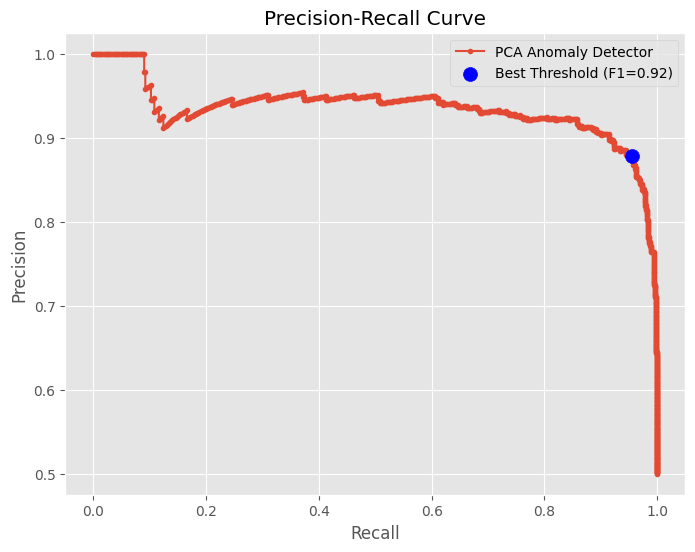

In [10]:
# --- YOUR TASK ---

# 1. Calculate Precision, Recall, and Thresholds
# The function calculates P and R for every possible threshold value in your data
# TODO: Use precision_recall_curve on y_test_combined and the reconstruction_error
precisions, recalls, thresholds = precision_recall_curve(y_test_combined, reconstruction_error)

# 2. Calculate F1 Scores for each threshold
# TODO: Calculate F1 = 2 * (P * R) / (P + R)
f1_scores = 2 * (precisions * recalls) / (precisions + recalls)
# Handle NaN values (if precision+recall is 0)
f1_scores = np.nan_to_num(f1_scores, nan=0.0)

# 3. Find optimal threshold (max F1)
# TODO: Find the index of the maximum F1 score
best_idx = np.argmax(f1_scores)
# TODO: Get the best threshold and best F1 score using the index
best_threshold = thresholds[best_idx]
best_f1 = f1_scores[best_idx]

# --- End of YOUR TASK ---

print(f"Optimal Reconstruction Error Threshold: {best_threshold:.4f}")
print(f"Best F1-Score: {best_f1:.4f}")

# Plot Precision-Recall Curve
plt.figure(figsize=(8, 6))
plt.plot(recalls, precisions, marker='.', label='PCA Anomaly Detector')
plt.scatter(recalls[best_idx], precisions[best_idx], color='blue', s=100, label=f'Best Threshold (F1={best_f1:.2f})', zorder=5)
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-Recall Curve')
plt.legend()
plt.grid(True)
plt.show()

### 4.4. **Visualizing the Results: Confusion Matrix & Failures** (`#TODO`)

Now that we have our `best_threshold`, let's put it to use! We will classify the test set and look at where the model succeeds and fails.

**The most interesting part is inspecting the errors:**

1. **False Positives (FP):** Normal T-shirts that the model thought were Sneakers. (Why? Maybe they have weird logos?)
2. **False Negatives (FN):** Sneakers that the model thought were T-shirts. (Why? Maybe they are shaped like a blob?)

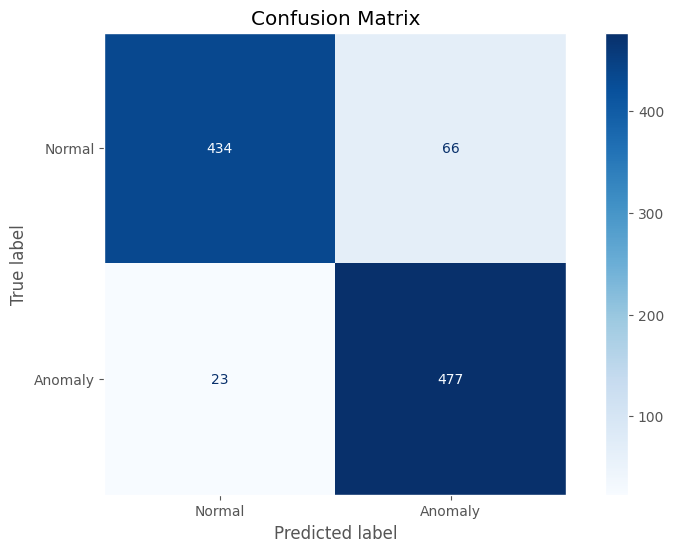

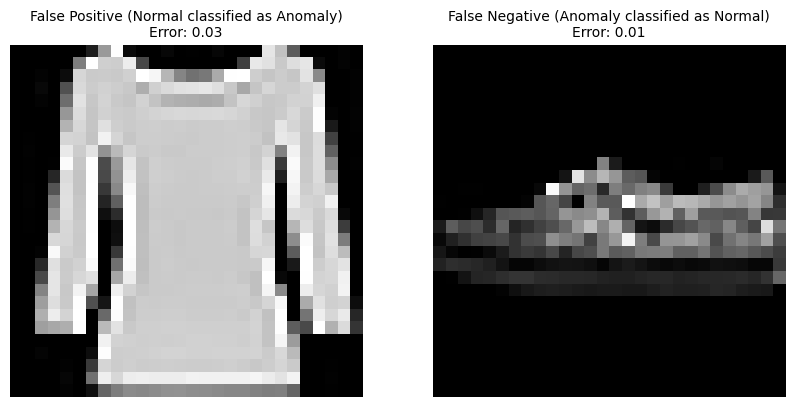

In [9]:
# --- YOUR TASK ---

# 1. Make Classifications using the Best Threshold
# If error > best_threshold -> Predict 1 (Anomaly/Sneaker)
# Else -> Predict 0 (Normal/T-shirt)
# TODO: Create a boolean array (or 0/1 integers) for predictions
y_pred = (reconstruction_error > best_threshold).astype(int)

# 2. Plot Confusion Matrix
# TODO: Use confusion_matrix to compare y_test_combined and y_pred
cm = confusion_matrix(y_test_combined, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Normal', 'Anomaly'])
disp.plot(cmap='Blues')
plt.title("Confusion Matrix")
plt.grid(False)
plt.show()

# 3. Visualize Failure Cases
# Let's find the indices of the errors to plot them
# TODO: Find indices where y_test is 0 but y_pred is 1 (False Positives)
fp_indices = np.where((y_test_combined == 0) & (y_pred == 1))[0]

# TODO: Find indices where y_test is 1 but y_pred is 0 (False Negatives)
fn_indices = np.where((y_test_combined == 1) & (y_pred == 0))[0]

# --- End of YOUR TASK ---

# Plot one False Positive and one False Negative
fig, axes = plt.subplots(1, 2, figsize=(10, 5))

if len(fp_indices) > 0:
    idx = fp_indices[0]
    axes[0].imshow(X_test_combined[idx].reshape(28, 28), cmap='gray')
    axes[0].set_title(f"False Positive (Normal classified as Anomaly)\nError: {reconstruction_error[idx]:.2f}", fontsize=10)
    axes[0].axis('off')
else:
    axes[0].text(0.5, 0.5, "No False Positives found!", ha='center')

if len(fn_indices) > 0:
    idx = fn_indices[0]
    axes[1].imshow(X_test_combined[idx].reshape(28, 28), cmap='gray')
    axes[1].set_title(f"False Negative (Anomaly classified as Normal)\nError: {reconstruction_error[idx]:.2f}", fontsize=10)
    axes[1].axis('off')
else:
    axes[1].text(0.5, 0.5, "No False Negatives found!", ha='center')

plt.show()

### 4.5. **Analysis: Question 3** (`#TODO`)

**Q3:** We arbitrarily chose `n_components=30` for our anomaly detector. Suppose we increased this number to `n_components=700` (using almost all available dimensions).

1. What would happen to the reconstruction error of the **Sneakers** (Anomalies)? Would it increase or decrease?
2. How would this affect the **Accuracy/F1-Score** of our Anomaly Detector? Would it get better or worse? Explain why.

**Answer:**
<p dir="rtl">
1. خطا کاهش پیدا میکند. 700 پیکسل نزدیک 784 پیکسل است و در نتیجه با خطای کمتر میتوان تصاویر را نمایش داد
2. با افزایش تعداد ویژگی ها مدل در بازسازی هر تصویری خوب عمل کرده و در نتیجه تفاوتی میان بازسازی تصاویر کفش و تیشرت وجود ندارد در نتیجه مدل در بازسازی هر دو خوب عمل کرده تفاوت بین خطای تیشرت و کفش ناچیز میشود در نتیجه نمیتوانیم آستانه پیدا کنیم که این دو را از هم جدا کند و سیستم قادر به تشخیص ناهنجاری نخواهد بود و حاصل دقت تقسیم بر F1 کم میشود
</p>

<div style="background-color: #e6f7ff; padding: 20px; border-radius: 10px; border: 1px solid #b3e0ff; text-align: center;">
  <h3 style="margin:0; color:#0056b3;">Congratulations!</h3>
  <p style="color:#333; font-size: 1.1em;">You have completed the sixth practical homework.</p>
</div>